# 02 - Classification arena (Titanic)
All numbers are loaded from CSVs produced by `scripts/run_classification.py` (5 seeds, same split for every model within a seed, inner 3-fold CV tuning on train only).

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd, matplotlib.pyplot as plt
from arena.config import RAW_DIR, SUMMARY_DIR, PRED_DIR
from arena.viz import leaderboard_bar
pd.set_option('display.width', 160)

In [2]:
raw = pd.read_csv(RAW_DIR / 'clf_baseline.csv')
lb = pd.read_csv(SUMMARY_DIR / 'leaderboard_clf.csv')
print(raw.seed.nunique(), 'seeds,', raw.model.nunique(), 'models')

5 seeds, 10 models


## Leaderboard (mean over seeds, with std)

In [3]:
wide = lb.pivot(index='model', columns='metric', values='mean')[['accuracy', 'f1', 'f1_macro']].sort_values('f1_macro', ascending=False)
std = lb.pivot(index='model', columns='metric', values='std')[['accuracy', 'f1', 'f1_macro']]
wide.round(4)

metric,accuracy,f1,f1_macro
model,,,
xgb,0.8458,0.7908,0.8343
rf,0.8391,0.7829,0.8275
dt,0.8391,0.7766,0.8254
dt_disc,0.8279,0.7508,0.8095
ada,0.8212,0.7602,0.8088
knn,0.8223,0.7543,0.8075
id3,0.8156,0.7331,0.7957
ann,0.8034,0.7308,0.7879
nc,0.7542,0.6833,0.7411


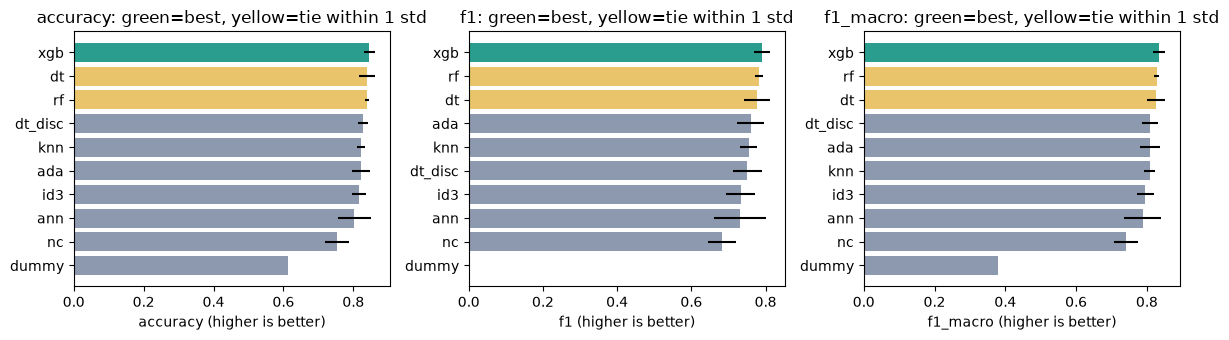

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, m in zip(axes, ['accuracy', 'f1', 'f1_macro']):
    leaderboard_bar(lb, m, ax)
plt.tight_layout()

## Best model per metric (with tie flag: a gap smaller than the leader's std is not a real win)

In [5]:
lb[lb.is_best | lb.tie_with_best][['metric','model','mean','std','is_best','tie_with_best']].round(4)

,metric,model,mean,std,is_best,tie_with_best
0,accuracy,xgb,0.8458,0.0161,True,False
1,accuracy,dt,0.8391,0.0221,False,True
2,accuracy,rf,0.8391,0.0061,False,True
10,f1,xgb,0.7908,0.0210,True,False
11,f1,rf,0.7829,0.0113,False,True
12,f1,dt,0.7766,0.0343,False,True
20,f1_macro,xgb,0.8343,0.0167,True,False
21,f1_macro,rf,0.8275,0.0072,False,True
22,f1_macro,dt,0.8254,0.0251,False,True
30,precision,dt_disc,0.8480,0.0430,True,False


## Cost: fit time (tuning included)

In [6]:
lb.drop_duplicates('model')[['model','fit_time_s']].sort_values('fit_time_s').round(2)

,model,fit_time_s
9,dummy,0.01
8,nc,0.09
3,dt_disc,0.10
6,id3,0.34
0,xgb,0.46
1,dt,0.48
7,ann,0.54
4,knn,1.10
5,ada,2.52
2,rf,5.67


## Tuned hyperparameters chosen (last seed shown)

In [7]:
raw[(raw.metric=='f1_macro') & (raw.seed==raw.seed.max())][['model','best_params']]

,model,best_params
244,dummy,{}
250,dt,"{""max_depth"": 8, ""min_samples_leaf"": 5}"
256,id3,"{""max_depth"": 3}"
262,dt_disc,"{""max_depth"": 5}"
268,knn,"{""n_neighbors"": 21, ""weights"": ""uniform""}"
274,nc,"{""metric"": ""manhattan""}"
279,ann,"{""alpha"": 0.0001, ""hidden_layer_sizes"": [64, 32]}"
285,rf,"{""max_depth"": 5, ""min_samples_leaf"": 3}"
291,ada,"{""learning_rate"": 1.0, ""n_estimators"": 50}"
297,xgb,"{""learning_rate"": 0.1, ""max_depth"": 3}"


**Reading the table:** models whose bars are yellow are statistically indistinguishable from the best given seed-to-seed variation. The Titanic test set has only ~179 rows, so small gaps are noise. ID3 is added to this table on Day 4.